# Track A — Customer Segmentation: RFM, CLV, Affinity, Persona
**Demo 18 phút.** Research sample cố định 10.000 khách, 17 tháng; full-cloud recommendation và evidence notebook gốc là các phạm vi khác.

Agenda: dữ liệu/EDA (3′) → event/lifecycle (2′) → RFM (2′) → CLV/SHAP (4′) → affinity (2′) → persona (3′) → handoff/giới hạn (2′).
Notebook chỉ đọc aggregate có sẵn trong GitHub; không cần raw Kaggle, credential, model pickle hoặc MLflow server để Run All.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'research/track_a/reports/sample_10k/summary.json').is_file())
REP = ROOT / 'research/track_a/reports/sample_10k'
summary = json.loads((REP / 'summary.json').read_text(encoding='utf-8'))
completed = json.loads((REP / 'completed.json').read_text(encoding='utf-8'))
assert completed['status'] == 'success'
assert summary['eda']['customers'] == 10000
display(pd.DataFrame([summary['eda']]).drop(columns=['cardinality','missing_share','absent_optional_columns']))

,rows,months,customers,first_month,last_month,mean_owned_products,mean_absence_or_incomplete_rate
0,143126,17,10000,2015-01,2016-05,1.46721,0.002294


## 1. Snapshot không phải transaction — EDA (3 phút)
Một dòng = một khách ở một tháng, 24 cờ ownership. Renta không phải số tiền giao dịch; panel absence không chứng minh rời ngân hàng. File raw đang dùng ở full pipeline khoảng 2,3 GB, không mặc định con số ~13 GB trong brief.

8 finding dưới đây được tính lại từ sample; các vấn đề của notebook EDA lịch sử được ghi trong limitations.md.

 — 8 finding có số đo

1. Có 143,126 snapshot, 17 tháng (2015-01–2016-05); không phải giao dịch/invoice.
2. Renta thiếu 20.37%; không coi renta là revenue hoặc giá trị giao dịch.
3. Age thiếu 0.14% ở raw; cleaning tuổi ngoài 0–110 thực hiện trong ingest v2, giữ khách trẻ.
4. Cardinality canal_entrada: 102; cần xử lý category chưa thấy khi scoring.
5. Cardinality segmento: 3 và pais_residencia: 21.
6. Trung bình 1.467 sản phẩm trên snapshot có đủ 24 cờ; bảng phân bố giữ riêng incomplete snapshot.
7. Trung bình 0.23% cohort complete hiện tại vắng/không đủ sản phẩm ở tháng kế. Đây không chứng minh rời ngân hàng.
8. Có 6,062 product-level acquisitions được xác minh bằng hai tháng liền kề; khách mới/gap return không tự tạo event.

Xem raw_column_audit.csv (có cod_prov/indrel_1mes), monthly_snapshots.csv, segment_product_trend.csv, portfolio_distribution.csv và panel_presence.csv.



,column,present,missing_n,missing_share,cardinality
0,age,True,194,0.001355,NaN
1,renta,True,29161,0.203744,NaN
2,cod_prov,True,783,0.005471,NaN
3,indrel_1mes,True,1439,0.010054,9.0
4,canal_entrada,True,1891,0.013212,102.0
5,segmento,True,1899,0.013268,3.0
6,pais_residencia,True,194,0.001355,21.0
7,ind_actividad_cliente,True,194,0.001355,NaN
8,indfall,True,194,0.001355,NaN
9,antiguedad,True,0,0.000000,NaN


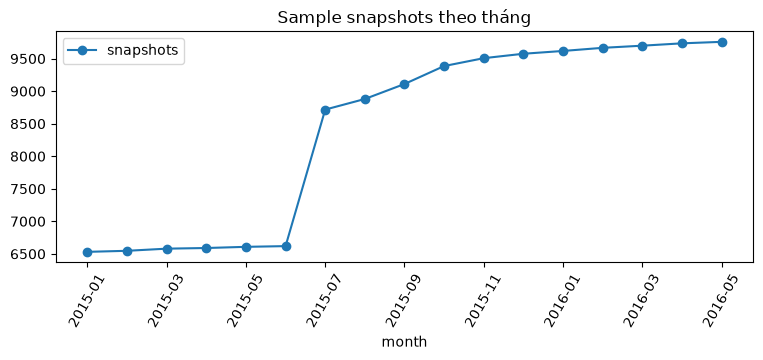

In [2]:
report = (REP / 'TRACK_A_REPORT.md').read_text(encoding='utf-8')
display(Markdown(report.split('## EDA')[1].split('## CLV')[0]))
display(pd.read_csv(REP / 'raw_column_audit.csv'))
monthly = pd.read_csv(REP / 'monthly_snapshots.csv')
monthly.plot(x='month', y='snapshots', marker='o', rot=60, title='Sample snapshots theo tháng', figsize=(9,3))
plt.show()

## 2. Acquisition event và lifecycle (2 phút)
Chỉ tính 0→1 trên hai tháng **liền kề và đủ 24 flag**, một dòng/product acquired. Nhiều sản phẩm trong một tháng vẫn chỉ một event-month cho BG/NBD/RFM F.

Giữ lifecycle presence của v2; lớp export bổ sung activity/death. Deceased → Churned/ineligible, inactive observed → At-risk trừ New/Win-back, thiếu status không tự thành eligible. Cohort và quy tắc trong feature spec.

In [3]:
display(pd.DataFrame([summary['events']]))
display(pd.DataFrame(summary['lifecycle'].items(), columns=['lifecycle','customers']))
display(pd.read_csv(REP / 'panel_presence.csv'))

,acquisition_rows,partitions
0,6062,16


,lifecycle,customers
0,At-risk,5685
1,Active,4062
2,Churned,165
3,New,87
4,Win-back,1


,origin,n_complete_current,absent_or_incomplete_next,absence_or_incomplete_rate
0,2015-01,6506,23,0.003535
1,2015-02,6526,19,0.002911
2,2015-03,6563,21,0.003200
3,2015-04,6573,20,0.003043
4,2015-05,6590,25,0.003794
5,2015-06,6608,0,0.000000
6,2015-07,8717,11,0.001262
7,2015-08,8880,13,0.001464
8,2015-09,9110,16,0.001756
9,2015-10,9386,20,0.002131


## 3. RFM: quantile / KMeans / rule (2 phút)
R = months since last observed acquisition, F = event-month count, M dùng current product count cho tiering. Portfolio propensity points trong ranker là feature khác, không phải monetary thật.

Fit cutoff 2015-11, giữ edges/scaler/centers cố định; duplicate quantiles được collapse. ARI và stay rate chỉ đo trên khách chung hai tháng, báo cả coverage. AP/Lift/Brier gốc nằm trong docs/02_benchmarks.md và không trộn cohort với bảng mới.

In [4]:
display(pd.read_csv(REP / 'rfm_geometry.csv').groupby('method')[['groups','silhouette']].mean())
rfm = pd.read_csv(REP / 'rfm_membership_stability.csv')
display(rfm.groupby('method')[['common_coverage','same_label_rate','adjusted_rand']].mean())

,groups,silhouette
method,,
kmeans_6,6.0,0.688838
quantile_333,7.0,0.582818
rule_based,21.0,0.589251


,common_coverage,same_label_rate,adjusted_rand
method,,,
kmeans_6,0.997733,0.952005,0.959446
quantile_333,0.997733,0.922096,0.956034
rule_based,0.997733,0.922366,0.970017


## 4. CLV-proxy 6 tháng: xác suất vs boosting (3 phút)
Cutoff 2015-11 → label end 2016-05. Train origins 03–05/2015, chỉ nhãn hoàn tất ≤ cutoff. Cùng cohort liên tục được quan sát, thiếu một cặp thì censored.

BG/NBD frequency = repeat events, recency = last-first event, T = cutoff-first event; khác RFM R. Gamma-Gamma dùng acquisitions/event-month làm value proxy, không phải money. Khách không đủ history dùng mean fallback, không gọi điểm toàn cohort là BG/NBD thuần.

Config 6m cố định, không có model selection qua validation 6m. Capture10 chia công bằng tie bằng expected fractional selection.

In [5]:
audit = json.loads((REP / 'clv_6m_audit.json').read_text())
assert audit['max_train_label_month'] <= audit['origin']
display(pd.DataFrame([{k:audit[k] for k in ['origin','label_end','train_rows','max_train_label_month','label_coverage']}]))
display(pd.read_csv(REP / 'clv_6m_benchmark.csv'))
display(pd.read_csv(REP / 'clv_probabilistic_fit_status.csv'))
errors = pd.read_csv(REP / 'clv_6m_segment_errors.csv')
display(errors.loc[errors.group_type.isin(['event_history','history_short'])])

,origin,label_end,train_rows,max_train_label_month,label_coverage
0,2015-11,2016-05,19533,2015-11,0.990533


,method,horizon_months,origin,fit_status,n,MAE,RMSE,actual_mean,predicted_mean,capture10,calibration_ratio
0,BGNBD,6,2015-11,fit,9417,0.452218,0.687539,0.236912,0.421937,0.532241,1.780985
1,BGNBD_GammaGamma,6,2015-11,fit,9417,0.460583,0.691939,0.236912,0.451120,0.508740,1.904168
2,gradient_boosting,6,2015-11,fit,9417,0.339316,0.656428,0.236912,0.340522,0.562976,1.437336
3,historical_mean,6,2015-11,fit,9417,0.459956,0.767239,0.236912,0.297804,0.100032,1.257023


,n_current,bg_eligible_n,gamma_eligible_n,fallback_share,horizon_months,method,status,penalizer,frequency_value_spearman,proxy_unit
0,9507,1514,745,0.840749,6,BGNBD,fit,0.01,NaN,NaN
1,9507,1514,745,0.840749,6,BGNBD_GammaGamma,fit,0.01,0.25279,products acquired per event-month; not money


,method,group_type,group,n,MAE,RMSE,actual_mean,predicted_mean,capture10,calibration_ratio
0,BGNBD,event_history,HasEvent,1610,0.957260,1.274025,1.008075,1.023865,0.188092,1.015664
1,BGNBD,event_history,NoObservedEvent,7807,0.348065,0.485244,0.077879,0.297804,0.100038,3.823937
2,BGNBD,history_short,False,8781,0.451479,0.684202,0.237672,0.427526,0.552741,1.798804
3,BGNBD,history_short,True,636,0.462420,0.732053,0.226415,0.344768,0.171072,1.522727
10,BGNBD_GammaGamma,event_history,HasEvent,1610,1.006189,1.287884,1.008075,1.194562,0.226741,1.184993
11,BGNBD_GammaGamma,event_history,NoObservedEvent,7807,0.348065,0.485244,0.077879,0.297804,0.100038,3.823937
12,BGNBD_GammaGamma,history_short,False,8781,0.459771,0.688067,0.237672,0.457555,0.531159,1.925153
13,BGNBD_GammaGamma,history_short,True,636,0.471789,0.743344,0.226415,0.362270,0.171072,1.600024
20,gradient_boosting,event_history,HasEvent,1610,0.992861,1.262409,1.008075,1.200546,0.197577,1.190930
21,gradient_boosting,event_history,NoObservedEvent,7807,0.204538,0.437154,0.077879,0.163163,0.422697,2.095093


### SHAP — giải thích model, không phải causal effect (1 phút)
Mean absolute SHAP trên 200 khách; additive reconstruction đã được kiểm tra với prediction thật của model. Poisson model có link log kỳ vọng acquisitions, không diễn giải raw SHAP là số tiền hoặc trực tiếp là delta acquisition.

,feature,mean_abs_shap,explained_n,link
0,n_products,0.448221,200,log_expected_acquisitions
1,R,0.360681,200,log_expected_acquisitions
2,antiguedad,0.290548,200,log_expected_acquisitions
3,M_group_points,0.203656,200,log_expected_acquisitions
4,age,0.100064,200,log_expected_acquisitions
5,renta,0.071202,200,log_expected_acquisitions
6,observed_pairs,0.053247,200,log_expected_acquisitions
7,relationship_age_months,0.049285,200,log_expected_acquisitions
8,F_event_months,0.012629,200,log_expected_acquisitions


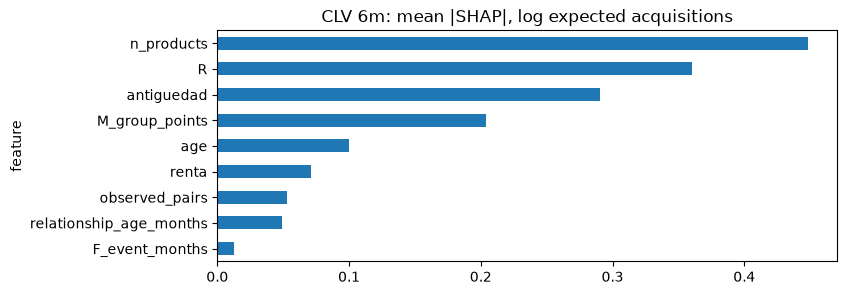

In [6]:
assert audit['explanation']['additive_reconstruction_verified']
importance = pd.read_csv(REP / 'clv_6m_shap_importance.csv')
display(importance)
importance.sort_values('mean_abs_shap').plot.barh(x='feature', y='mean_abs_shap', legend=False,
    title='CLV 6m: mean |SHAP|, log expected acquisitions', figsize=(8,3))
plt.show()

## 5. Affinity và next-product quality (2 phút)
Ma trận 24×24 có counts, support, confidence và lift. Bảng tháng cuối là mô tả; next-month benchmark fit ở origin và chấm ở tháng sau, mask sản phẩm đã có.

Notebook 06 gốc có Apriori itemsets đến 3 và item2vec SGNS, cùng benchmark được giữ trong docs/02_benchmarks.md. Kết quả item2vec cấu hình gốc thấp; không che kết quả đó hoặc gọi co-occurrence SVD là item2vec.

,method,origin,n_all,n_buyers,buyer_prevalence,map_at_7_all,map_at_7_buyers,recall_at_7_buyers,recommendation_coverage
0,coownership_confidence,2016-04,9710,300,0.030896,0.018369,0.594559,0.930833,1.0
1,past_acquisition_popularity,2016-04,9710,300,0.030896,0.020546,0.665017,0.977778,1.0


,antecedent,consequent,count,support,confidence,lift
205,ind_nomina_ult1,ind_nom_pens_ult1,515,0.052777,1.000000,17.119298
220,ind_nom_pens_ult1,ind_nomina_ult1,515,0.052777,0.903509,17.119298
108,ind_fond_fin_ult1,ind_plan_fin_ult1,16,0.001640,0.117647,14.350000
132,ind_plan_fin_ult1,ind_fond_fin_ult1,16,0.001640,0.200000,14.350000
31,ind_cno_fin_ult1,ind_nom_pens_ult1,523,0.053597,0.673969,11.537878
208,ind_nom_pens_ult1,ind_cno_fin_ult1,523,0.053597,0.917544,11.537878
193,ind_nomina_ult1,ind_cno_fin_ult1,471,0.048268,0.914563,11.500395
30,ind_cno_fin_ult1,ind_nomina_ult1,471,0.048268,0.606959,11.500395
111,ind_fond_fin_ult1,ind_valo_fin_ult1,33,0.003382,0.242647,10.162017
179,ind_valo_fin_ult1,ind_fond_fin_ult1,33,0.003382,0.141631,10.162017


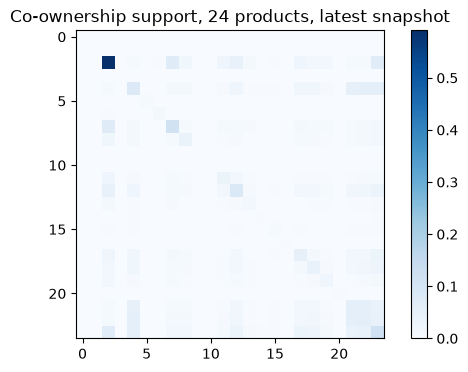

In [7]:
display(pd.read_csv(REP / 'affinity_next_month_benchmark.csv'))
rules = pd.read_csv(REP / 'affinity_pair_rules.csv')
display(rules.sort_values(['lift','count'], ascending=False).head(10))
matrix = pd.read_csv(REP / 'affinity_support_24x24.csv', index_col=0)
fig, ax = plt.subplots(figsize=(7,4))
image = ax.imshow(matrix, cmap='Blues')
ax.set_title('Co-ownership support, 24 products, latest snapshot')
fig.colorbar(image, ax=ax)
plt.show()

## 6. Persona có diễn giải và kiểm tra stability (3 phút)
Nghiên cứu gốc có 6 card P1–P6 theo rule với số đo/provenance đầy đủ. Phương án mới C1–Ck gom cả RFM, CLV, portfolio, affinity, age/renta/tenure, canal và segmento.

Chọn k=5…8 bằng fit-only silhouette và min-share ≥1%, không dùng acquisition labels để chọn k. Bootstrap ARI và temporal ARI/stay rate được báo riêng; mean profile ổn định không chứng minh membership ổn định. Business action vẫn là giả thuyết cần A/B test.

In [8]:
display(pd.read_csv(REP / 'persona_k_selection.csv'))
display(pd.read_csv(REP / 'persona_cluster_profiles.csv'))
display(pd.read_csv(REP / 'persona_bootstrap_stability.csv'))
display(pd.read_csv(REP / 'persona_temporal_stability.csv'))
display(Markdown((REP / 'persona_cluster_cards.md').read_text(encoding='utf-8')))

,k,silhouette,min_cluster_share,inertia
0,5,0.270085,0.032082,54764.914051
1,6,0.256777,0.031871,50303.472036
2,7,0.254777,0.031345,46949.961060
3,8,0.247497,0.031135,45030.649766


,persona,n,share,median_age,income_coverage,median_income,median_tenure,median_F,median_n_products,mean_clv_1m,top_product,top_product_ownership,top_channel,top_channel_share
0,C1,347,0.035561,40.0,0.711816,106448.670,44.0,2.0,2.0,0.410111,ind_cno_fin_ult1,0.766571,KAT,0.291066
1,C2,3457,0.354273,24.0,0.695690,87437.400,31.0,0.0,1.0,0.034788,ind_cco_fin_ult1,0.722592,KHE,0.662135
2,C3,1346,0.137938,43.0,0.762259,106316.085,56.0,1.0,2.0,0.062070,ind_cco_fin_ult1,0.694651,KFC,0.280089
3,C4,4142,0.424472,49.0,0.817962,108754.410,123.0,0.0,1.0,0.029550,ind_cco_fin_ult1,0.481410,KFC,0.360937
4,C5,466,0.047756,42.0,0.695279,110474.865,53.5,3.0,3.0,0.087194,ind_cco_fin_ult1,0.645923,KAT,0.287554


,seed,adjusted_rand
0,43,0.739101
1,44,0.993431
2,45,0.733256


,source_month,target_month,common_n,common_coverage,same_label_rate,adjusted_rand
0,2015-11,2015-12,9486,0.997791,0.931900,0.939947
1,2015-12,2016-01,9546,0.996971,0.927614,0.921507
2,2016-01,2016-02,9602,0.998336,0.915122,0.920413
3,2016-02,2016-03,9644,0.997724,0.941207,0.943654
4,2016-03,2016-04,9681,0.998144,0.931515,0.931458
5,2016-04,2016-05,9710,0.997432,0.944284,0.952080


# Persona clustering — hồ sơ định lượng

KMeans k=5, fit tại 2015-11; mô tả tại 2016-05. CLV là số acquisition dự báo một tháng, không phải tiền.

Các cluster C1…Ck là phương án nghiên cứu bổ sung; không thay nhãn P1–P6 theo rule đang dùng trong ranker.


## C1 — Có lịch sử mở thêm sản phẩm, danh mục hẹp

- Quy mô: 347 (3.6%); tuổi median 40.0; tenure median 44.0 tháng.
- F median 2.0; số sản phẩm median 2.0; CLV-proxy mean 0.4101 acquisition/khách/tháng.
- Renta median 106448.7, coverage 71.2%; không diễn giải là lợi nhuận.
- Sản phẩm phổ biến nhất: ind_cno_fin_ult1 (76.7%); canal KAT (29.1%).
- Gợi ý business cần kiểm thử: dùng affinity để chọn sản phẩm chưa sở hữu, CLV để ưu tiên và lifecycle/activity để lọc eligibility; chưa đo uplift chiến dịch.


## C2 — Chưa ghi nhận acquisition ở khách điển hình, danh mục hẹp

- Quy mô: 3,457 (35.4%); tuổi median 24.0; tenure median 31.0 tháng.
- F median 0.0; số sản phẩm median 1.0; CLV-proxy mean 0.0348 acquisition/khách/tháng.
- Renta median 87437.4, coverage 69.6%; không diễn giải là lợi nhuận.
- Sản phẩm phổ biến nhất: ind_cco_fin_ult1 (72.3%); canal KHE (66.2%).
- Gợi ý business cần kiểm thử: dùng affinity để chọn sản phẩm chưa sở hữu, CLV để ưu tiên và lifecycle/activity để lọc eligibility; chưa đo uplift chiến dịch.


## C3 — Có lịch sử mở thêm sản phẩm, danh mục hẹp

- Quy mô: 1,346 (13.8%); tuổi median 43.0; tenure median 56.0 tháng.
- F median 1.0; số sản phẩm median 2.0; CLV-proxy mean 0.0621 acquisition/khách/tháng.
- Renta median 106316.1, coverage 76.2%; không diễn giải là lợi nhuận.
- Sản phẩm phổ biến nhất: ind_cco_fin_ult1 (69.5%); canal KFC (28.0%).
- Gợi ý business cần kiểm thử: dùng affinity để chọn sản phẩm chưa sở hữu, CLV để ưu tiên và lifecycle/activity để lọc eligibility; chưa đo uplift chiến dịch.


## C4 — Chưa ghi nhận acquisition ở khách điển hình, danh mục hẹp

- Quy mô: 4,142 (42.4%); tuổi median 49.0; tenure median 123.0 tháng.
- F median 0.0; số sản phẩm median 1.0; CLV-proxy mean 0.0296 acquisition/khách/tháng.
- Renta median 108754.4, coverage 81.8%; không diễn giải là lợi nhuận.
- Sản phẩm phổ biến nhất: ind_cco_fin_ult1 (48.1%); canal KFC (36.1%).
- Gợi ý business cần kiểm thử: dùng affinity để chọn sản phẩm chưa sở hữu, CLV để ưu tiên và lifecycle/activity để lọc eligibility; chưa đo uplift chiến dịch.


## C5 — Có lịch sử mở thêm sản phẩm, danh mục đa sản phẩm

- Quy mô: 466 (4.8%); tuổi median 42.0; tenure median 53.5 tháng.
- F median 3.0; số sản phẩm median 3.0; CLV-proxy mean 0.0872 acquisition/khách/tháng.
- Renta median 110474.9, coverage 69.5%; không diễn giải là lợi nhuận.
- Sản phẩm phổ biến nhất: ind_cco_fin_ult1 (64.6%); canal KAT (28.8%).
- Gợi ý business cần kiểm thử: dùng affinity để chọn sản phẩm chưa sở hữu, CLV để ưu tiên và lifecycle/activity để lọc eligibility; chưa đo uplift chiến dịch.


## 7. Feature spec, reproducibility và storage (1 phút)
Entity customer_id, grain customer/month, snake_case, source versions, actual availability và TTL 45 ngày tối đa/invalidate on next snapshot. Không join label tương lai vào feature, không carry-forward qua panel absence.

Processed customer table/event partitions không đưa lên GitHub. `processed_manifest.json` giữ file list/size/SHA256; S3 exporter dry-run mặc định và cần bucket/prefix để upload thật. GCS của recommendation pipeline không tự được coi là đáp ứng yêu cầu AWS S3.

MLflow experiment `santander-track-a`; log aggregate, không log raw hoặc customer-level records.

In [9]:
spec = json.loads((REP / 'feature_store_spec.json').read_text())
display(pd.DataFrame(spec['schema']).head(20))
display(pd.DataFrame([{'view':spec['feature_view'], 'ttl':spec['ttl'], 'refresh':spec['refresh'],
    'mlflow_experiment_id':completed['mlflow']['experiment_id'],
    'mlflow_parent_run':completed['mlflow']['parent_run_id']}]))

,name,dtype,nullable,role,definition
0,customer_id,int64,False,entity,"Santander ncodpers; join key only, never a mod..."
1,sexo,string,False,feature,Source field/quality metadata defined in event...
2,age,float64,True,feature,Source field/quality metadata defined in event...
3,fecha_alta,datetime64[ns],False,feature,Source field/quality metadata defined in event...
4,antiguedad,float64,False,feature,Source field/quality metadata defined in event...
5,canal_entrada,string,False,feature,Source field/quality metadata defined in event...
6,nomprov,string,False,feature,Source field/quality metadata defined in event...
7,renta,float64,True,feature,Source field/quality metadata defined in event...
8,segmento,string,False,feature,Source field/quality metadata defined in event...
9,ind_ahor_fin_ult1,float32,False,feature,Current 0/1 ownership flag; incomplete portfol...


,view,ttl,refresh,mlflow_experiment_id,mlflow_parent_run
0,santander_track_a_customer_month_v1,"45 days maximum, invalidate on next snapshot",monthly and on corrected upstream snapshots,2,0ea405f68cda46588971b40dc2a6a63f


## 8. Kết luận và giới hạn (1 phút)
- RFM/CLV là proxy khi không có transaction hoặc monetary thật; không dùng từ lợi nhuận đã đo.
- 6m có một development backtest với cấu hình cố định, chưa là validation độc lập/holdout. 12m chưa đủ lịch sử cho supervised train/validation/test đáng tin.
- BG/NBD/Gamma-Gamma dựa trên giả định retail; phần lớn cohort dùng fallback. Catalog hữu hạn/reopen/thời gian tháng là giới hạn.
- Selection bias do cần future complete pairs; cluster stability không phải marketing uplift.
- Bộ nghiên cứu và benchmark sample đã có; upload S3 thật cần destination và receipt.

**Tài liệu hội đồng:** [đối chiếu track](../docs/TRACK_A_AUDIT.md), [report](../reports/sample_10k/TRACK_A_REPORT.md), [6 persona rule cards](../docs/04_persona_cards.md), [feature spec](../docs/FEATURE_STORE_SPEC.md), [cách chạy lại](../docs/REPRODUCE.md).